In [1]:
# Install required libraries
!pip install -q tensorflow scikit-learn pandas numpy matplotlib

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from google.colab import files

print("Please upload random_stock_market_dataset.csv")
uploaded = files.upload()

Please upload random_stock_market_dataset.csv


Saving random_stock_market_dataset.csv to random_stock_market_dataset (1).csv


In [3]:
# Load the uploaded CSV file
df = pd.read_csv("random_stock_market_dataset.csv")

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nLast 5 rows:")
print(df.tail())

print("\nDataset information:")
print(df.info())

Dataset shape: (60, 6)

First 5 rows:
         Date    Open    High     Low   Close  Volume
0  2024-01-01  296.45  307.31  293.96  303.72   93133
1  2024-01-02  190.11  193.10  187.21  191.40   64993
2  2024-01-03  197.41  208.64  193.37  205.89   70326
3  2024-01-04  253.13  262.67  248.67  258.95   17358
4  2024-01-05  241.35  253.09  238.99  252.20   20847

Last 5 rows:
          Date    Open    High     Low   Close  Volume
55  2024-02-25  170.55  181.13  167.39  178.58   47071
56  2024-02-26  187.88  195.26  186.36  193.36  115659
57  2024-02-27  355.67  375.14  353.60  370.56   62294
58  2024-02-28  289.90  298.27  289.06  298.01  108022
59  2024-02-29  120.34  131.84  116.30  129.95   64201

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    60 non-null     object 
 1   Open    60 non-null     float64
 2   High    60 non-nu

In [4]:
# Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Sort data from oldest date to newest date
df = df.sort_values('Date').reset_index(drop=True)

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove missing values
df = df.dropna().reset_index(drop=True)

# Remove duplicate dates
df = df.drop_duplicates(subset='Date').reset_index(drop=True)

print("\nDataset shape after cleaning:", df.shape)
print(df.head())

Missing values before cleaning:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Dataset shape after cleaning: (60, 6)
        Date    Open    High     Low   Close  Volume
0 2024-01-01  296.45  307.31  293.96  303.72   93133
1 2024-01-02  190.11  193.10  187.21  191.40   64993
2 2024-01-03  197.41  208.64  193.37  205.89   70326
3 2024-01-04  253.13  262.67  248.67  258.95   17358
4 2024-01-05  241.35  253.09  238.99  252.20   20847


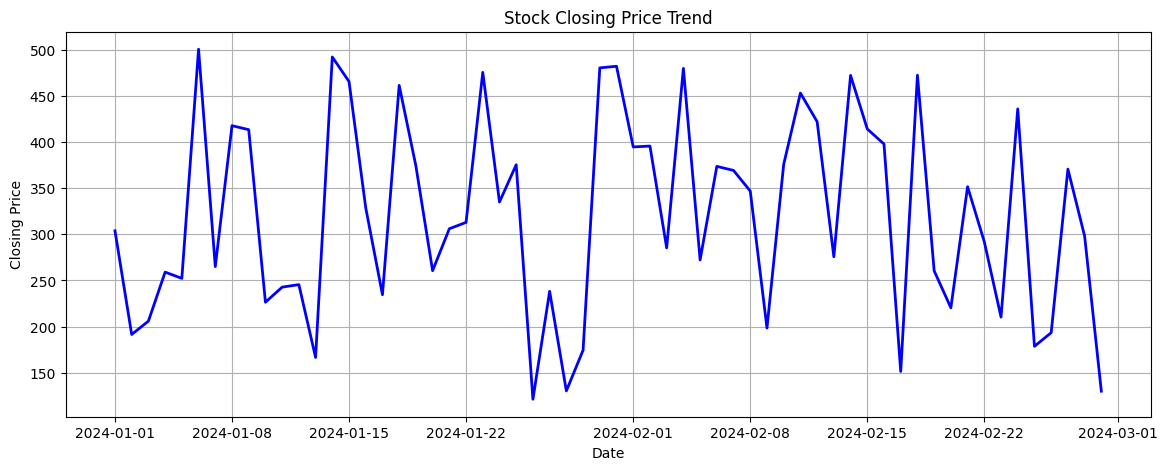

In [5]:
# Plot historical closing price trend
plt.figure(figsize=(14, 5))
plt.plot(df['Date'], df['Close'], color='blue', linewidth=2)
plt.title('Stock Closing Price Trend')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.grid(True)
plt.show()

In [6]:
# Features used for prediction
feature_columns = ['Open', 'High', 'Low', 'Close', 'Volume']

# Target column: next day's closing price
target_column = 'Close'

# Normalize input features between 0 and 1
feature_scaler = MinMaxScaler()
scaled_features = feature_scaler.fit_transform(df[feature_columns])

# Normalize target separately
target_scaler = MinMaxScaler()
scaled_target = target_scaler.fit_transform(df[[target_column]])

print("Scaled features shape:", scaled_features.shape)
print("Scaled target shape:", scaled_target.shape)

Scaled features shape: (60, 5)
Scaled target shape: (60, 1)


In [7]:
# Use previous 10 days to predict next day's Close price
WINDOW_SIZE = 10

X = []
y = []

for i in range(WINDOW_SIZE, len(scaled_features)):
    X.append(scaled_features[i-WINDOW_SIZE:i])   # previous 10 days
    y.append(scaled_target[i])                   # next day's Close price

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (50, 10, 5)
y shape: (50, 1)


In [8]:
# Chronological split: first 80% training, last 20% testing
split_index = int(len(X) * 0.8)

X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = y[:split_index], y[split_index:]

print("Training samples:", X_train.shape)
print("Testing samples :", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets :", y_test.shape)

Training samples: (40, 10, 5)
Testing samples : (10, 10, 5)
Training targets: (40, 1)
Testing targets : (10, 1)


In [9]:
# Build LSTM model
model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(WINDOW_SIZE, X.shape[2])),
    Dropout(0.2),

    LSTM(32, return_sequences=False),
    Dropout(0.2),

    Dense(16, activation='relu'),
    Dense(1)
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 10, 64)         │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,881 (120.63 KB)

 Trainable params: 30,881 (120.63 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Compile model
model.compile(
    loss='mse',
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics=['mae']
)

# Stop training when validation loss stops improving
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# Train model
history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 177ms/step - loss: 0.4769 - mae: 0.6353 - val_loss: 0.2886 - val_mae: 0.4357
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.3013 - mae: 0.4825 - val_loss: 0.1774 - val_mae: 0.3561
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.1963 - mae: 0.3757 - val_loss: 0.1179 - val_mae: 0.3044
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.1371 - mae: 0.3102 - val_loss: 0.1150 - val_mae: 0.3051
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.0997 - mae: 0.2683 - val_loss: 0.1560 - val_mae: 0.3110
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0972 - mae: 0.2718 - val_loss: 0.1743 - val_mae: 0.3303
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.1027 - mae: 0.2632 - val_loss: 0.1481 - val_mae: 0.3050
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.0997 - mae: 0.2521 - val_loss: 0.1170 - val_mae: 0.3048
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 0.0969 - mae:

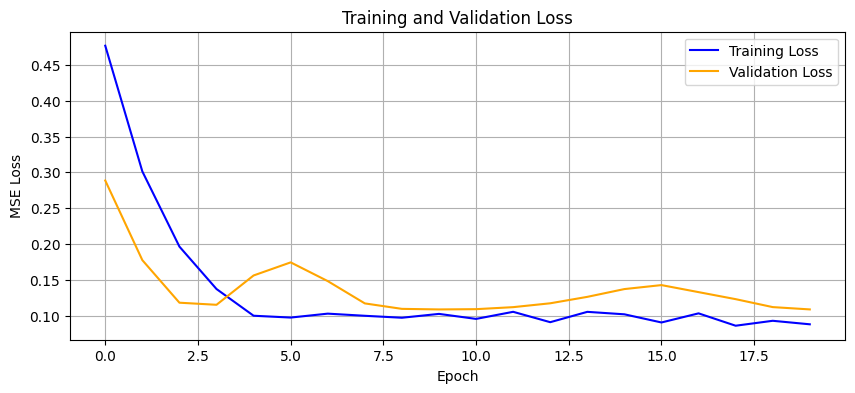

In [11]:
# Plot training and validation loss
plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Training Loss', color='blue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True)
plt.show()

In [12]:
# Predict on test data
y_pred_scaled = model.predict(X_test)

# Convert normalized values back to actual price scale
y_pred = target_scaler.inverse_transform(y_pred_scaled)
y_actual = target_scaler.inverse_transform(y_test)

# Show comparison
comparison = pd.DataFrame({
    'Actual Close Price': y_actual.flatten(),
    'Predicted Close Price': y_pred.flatten()
})

print(comparison)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 316ms/step
   Actual Close Price  Predicted Close Price
0              220.31             330.685791
1              351.46             324.531403
2              291.79             316.404510
3              210.20             309.254547
4              435.79             306.005493
5              178.58             298.282837
6              193.36             290.406830
7              370.56             281.459747
8              298.01             287.735443
9              129.95             278.280731


In [13]:
# Calculate MAE and RMSE
mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")

MAE  : 85.5213
RMSE : 96.9345


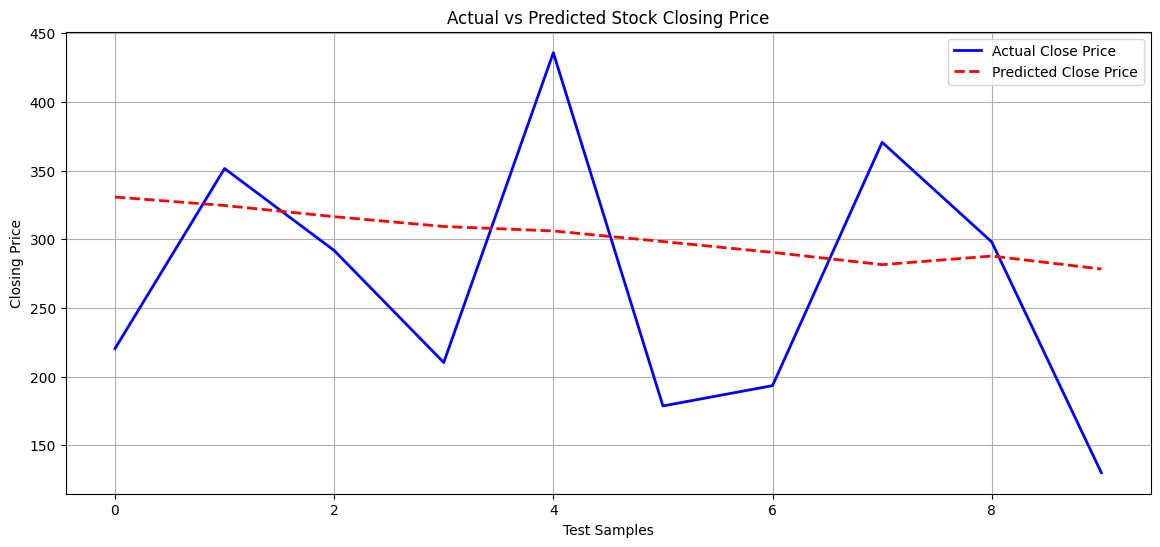

In [14]:
# Plot actual vs predicted closing price
plt.figure(figsize=(14, 6))
plt.plot(y_actual, label='Actual Close Price', color='blue', linewidth=2)
plt.plot(y_pred, label='Predicted Close Price', color='red', linewidth=2, linestyle='--')
plt.title('Actual vs Predicted Stock Closing Price')
plt.xlabel('Test Samples')
plt.ylabel('Closing Price')
plt.legend()
plt.grid(True)
plt.show()

In [15]:
# Use the last 10 days to predict the next unseen day
last_10_days = scaled_features[-WINDOW_SIZE:]
last_10_days = np.reshape(last_10_days, (1, WINDOW_SIZE, X.shape[2]))

next_day_scaled = model.predict(last_10_days)
next_day_price = target_scaler.inverse_transform(next_day_scaled)

print("Predicted next-day closing price:", round(float(next_day_price[0][0]), 2))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step
Predicted next-day closing price: 276.01


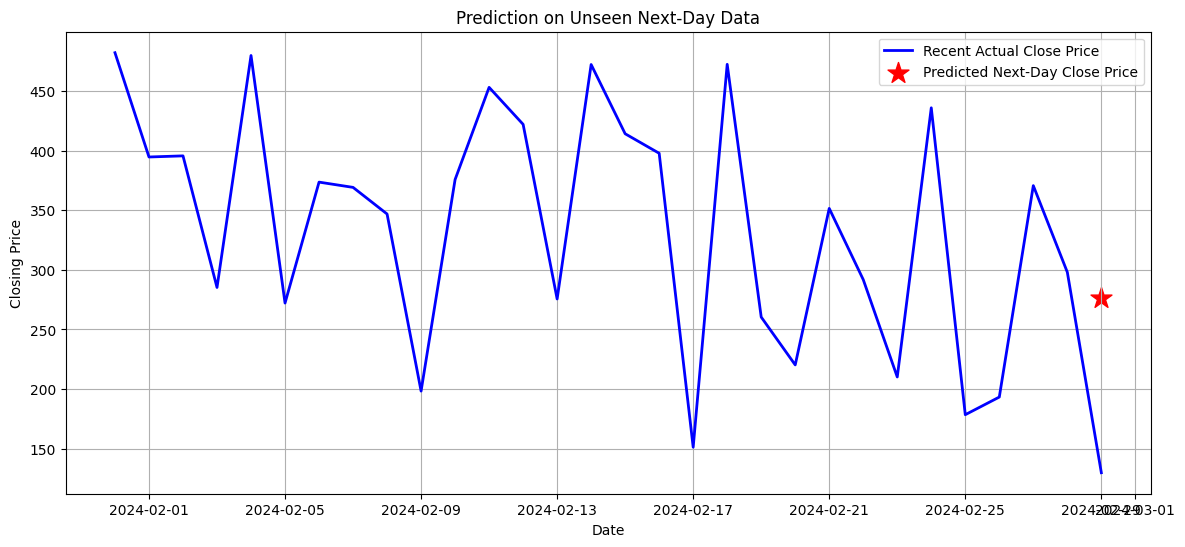

In [16]:
# Plot recent actual prices and predicted next-day price
plt.figure(figsize=(14, 6))
plt.plot(df['Date'].iloc[-30:], df['Close'].iloc[-30:],
         label='Recent Actual Close Price', color='blue', linewidth=2)

plt.scatter(df['Date'].iloc[-1], next_day_price[0][0],
            color='red', marker='*', s=250,
            label='Predicted Next-Day Close Price')

plt.title('Prediction on Unseen Next-Day Data')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.grid(True)
plt.show()

In [17]:
# Save trained model
model.save("stock_price_lstm_model.keras")
print("Model saved successfully.")

Model saved successfully.
